In [1]:
# Google Colab Only
try:
    import google.colab  # noqa: F401

    # specify the version of DataEval (==X.XX.X) for versions other than the latest
    %pip install -q dataeval[opencv] "maite-datasets[hf]>=0.0.25" "dataeval-plots>=0.0.19"
except Exception:
    pass

In [2]:
import warnings

import dataeval_plots as dep
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from IPython.display import display
from maite_datasets.multiobject_tracking import VisDroneMOT

from dataeval import Metadata
from dataeval.config import set_max_processes
from dataeval.core import ego_stats, image_stats, track_stats
from dataeval.data import Indices, SequenceFrames, View
from dataeval.exceptions import ExperimentalWarning
from dataeval.flags import ImageStats
from dataeval.quality import Duplicates

set_max_processes(4)
_ = pl.Config.set_tbl_width_chars(160)
# Reading rows bins the frame counts, which this tutorial does not use.
warnings.filterwarnings("ignore", message=".*binned automatically")
# Edge directionality is experimental.
warnings.filterwarnings("ignore", category=ExperimentalWarning)

In [3]:
dataset = VisDroneMOT(root="./data", image_set="val", download=True)
metadata = Metadata(dataset)

In [4]:
VEHICLES = ["car", "van", "truck", "bus"]
vehicle_ids = [index for index, name in dataset.index2label.items() if name in VEHICLES]

boxes = (
    metadata
    .rows_at("instance")
    .filter(pl.col("class_label").is_in(vehicle_ids))
    .with_columns(
        box_width=pl.col("box").arr.get(2) - pl.col("box").arr.get(0),
        box_height=pl.col("box").arr.get(3) - pl.col("box").arr.get(1),
    )
)
frames = (
    metadata
    .rows_at("unit")
    .group_by("item_index")
    .agg(pl.len().alias("frames"), pl.col("width").first(), pl.col("height").first())
)
vehicles = boxes.group_by("item_index").agg(
    pl.len().alias("vehicle_boxes"), pl.col("track_id").n_unique().alias("vehicle_tracks")
)
videos = (
    metadata
    .rows_at("sequence")
    .select("item_index", pl.col("item_id").alias("video"), "scene_type", "time_of_day")
    .join(frames, on="item_index")
    .join(vehicles, on="item_index", how="left")
    .fill_null(0)
    .sort("item_index")
)
item_of = dict(zip(videos["video"], videos["item_index"], strict=True))
display(videos.drop("item_index"))

video,scene_type,time_of_day,frames,width,height,vehicle_boxes,vehicle_tracks
str,str,str,u32,i64,i64,u32,u32
"""uav0000086_00000_v""","""sporting event""","""daytime""",464,1344,756,0,0
"""uav0000117_02622_v""","""intersection""","""night""",349,2720,1530,5505,28
"""uav0000137_00458_v""","""intersection""","""daytime""",233,2688,1512,7060,44
"""uav0000182_00000_v""","""road""","""daytime""",363,1344,756,8177,59
"""uav0000268_05773_v""","""road""","""daytime""",978,3840,2160,11084,44
"""uav0000305_00000_v""","""intersection""","""daytime""",184,1904,1071,4500,48
"""uav0000339_00001_v""","""intersection""","""dusk""",275,1904,1071,3960,23


In [5]:
# TEST ASSERTION CELL ###
assert len(dataset) == 7
assert metadata.rows_at("unit").height == 2846
assert metadata.rows_at("track").height == 758
assert metadata.rows_at("instance").height == 114132
assert boxes.height == 40286
assert boxes.select("item_index", "track_id").n_unique() == 246
by_video = {r["video"]: r for r in videos.iter_rows(named=True)}
assert by_video["uav0000268_05773_v"]["frames"] == 978
assert videos.filter(pl.col("scene_type") != "intersection")["frames"].sum() == 1805
assert videos.filter(pl.col("scene_type") != "intersection").height == 3
night = videos.filter(pl.col("time_of_day") == "night")
assert night.height == 1
assert night["vehicle_boxes"][0] == 5505
assert night["vehicle_tracks"][0] == 28
assert videos.filter(pl.col("time_of_day") == "dusk").height == 1
assert by_video["uav0000086_00000_v"]["vehicle_boxes"] == 0

In [6]:
redundancy = Duplicates().evaluate(dataset).aggregate_by_sequence().sort("sequence")
display(
    redundancy
    .join(videos.select(pl.col("item_index").alias("sequence"), "video"), on="sequence")
    .select("video", "n_frames", "redundant_fraction", "longest_run", "shared_with")
    .sort("video")
)

video,n_frames,redundant_fraction,longest_run,shared_with
str,u32,f64,u32,u32
"""uav0000086_00000_v""",464,0.997845,464,0
"""uav0000117_02622_v""",349,0.979943,199,0
"""uav0000137_00458_v""",233,0.922747,144,0
"""uav0000182_00000_v""",363,0.958678,202,0
"""uav0000268_05773_v""",978,0.998978,978,0
"""uav0000305_00000_v""",184,0.793478,147,0
"""uav0000339_00001_v""",275,0.927273,95,0


In [7]:
# TEST ASSERTION CELL ###
frac = redundancy["redundant_fraction"].to_numpy()
assert 0.94 <= redundancy["redundant_frames"].to_numpy().sum() / redundancy["n_frames"].to_numpy().sum() <= 0.98
assert 0.785 <= frac.min() <= 0.80
assert frac.max() >= 0.995
assert (redundancy["shared_with"] == 0).all()
whole = redundancy.filter(pl.col("longest_run") == pl.col("n_frames"))["sequence"].to_list()
assert whole == sorted([item_of["uav0000086_00000_v"], item_of["uav0000268_05773_v"]])

In [8]:
camera = ego_stats(dataset)["stats"]
motion = pl.DataFrame({name: values for name, values in camera.items() if name != "motion"})

In [9]:
road_item = item_of["uav0000182_00000_v"]
edges = image_stats(
    SequenceFrames(View(dataset, Indices([road_item]))),
    stats=ImageStats.VISUAL_BLUR_EDGE_DIRECTIONALITY,
    per_target=False,
)
road = (
    motion
    .filter(pl.col("item_index") == road_item)
    .sort("unit_index")
    .with_columns(frame=pl.int_range(pl.len()), blur_edge_directionality=edges["stats"]["blur_edge_directionality"])
    .filter(pl.col("ego_trusted"))
)
fast = road["pan_speed"] > road["pan_speed"].quantile(0.75)
display(
    road
    .with_columns(fastest_quarter=fast)
    .group_by("fastest_quarter")
    .agg(pl.len().alias("frames"), pl.col("pan_speed").median(), pl.col("blur_edge_directionality").median())
    .sort("fastest_quarter")
)

fastest_quarter,frames,pan_speed,blur_edge_directionality
bool,u32,f64,f32
false,272,1.742335,0.00898
true,90,12.783503,0.270383


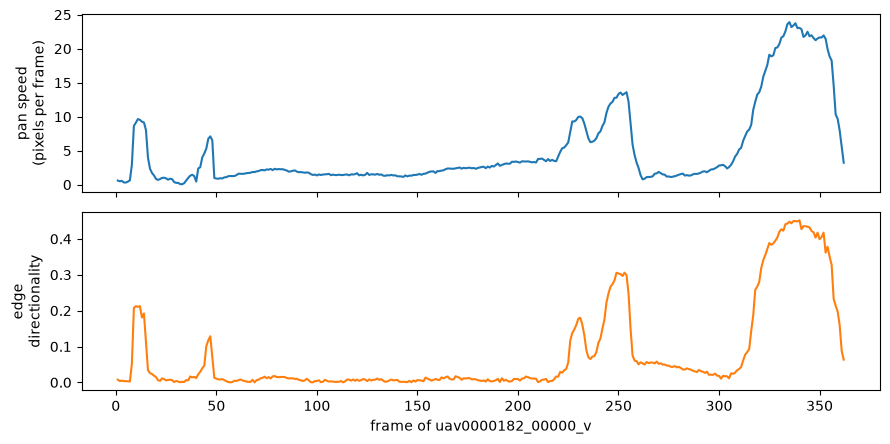

In [10]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
top.plot(road["frame"], road["pan_speed"], color="tab:blue")
top.set_ylabel("pan speed\n(pixels per frame)")
bottom.plot(road["frame"], road["blur_edge_directionality"], color="tab:orange")
bottom.set_ylabel("edge\ndirectionality")
bottom.set_xlabel("frame of uav0000182_00000_v")
fig.tight_layout()
plt.show()

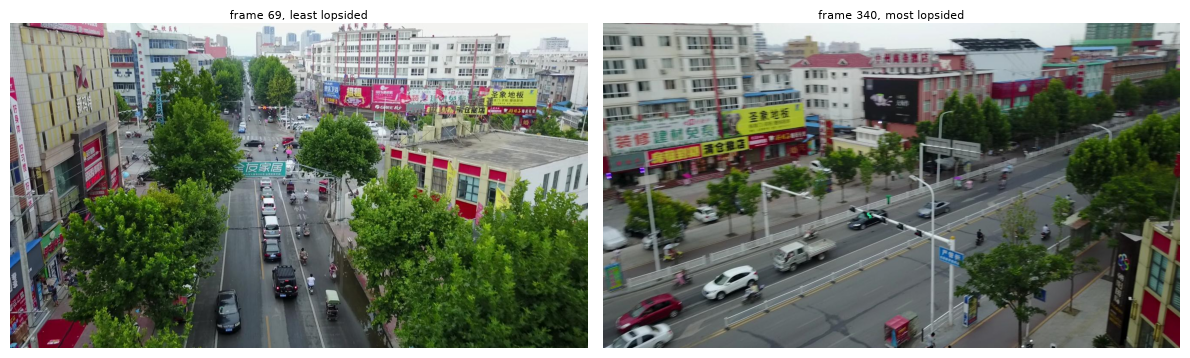

In [11]:
road_frames = SequenceFrames(View(dataset, Indices([road_item])))
least = road.sort("blur_edge_directionality")["frame"][0]
most = road.sort("blur_edge_directionality")["frame"][-1]
dep.plot(
    road_frames,
    figsize=(12, 3.6),
    indices=[int(least), int(most)],
    images_per_row=2,
    titles=[f"frame {least}, least lopsided", f"frame {most}, most lopsided"],
    boxes=False,
)

In [12]:
# TEST ASSERTION CELL ###
assert motion.filter(pl.col("item_index") == road_item)["ego_trusted"].to_numpy().mean() >= 0.99
slow_dir = np.median(road.filter(~fast)["blur_edge_directionality"].to_numpy())
fast_dir = np.median(road.filter(fast)["blur_edge_directionality"].to_numpy())
assert slow_dir < 0.03
assert fast_dir > 0.15
assert fast_dir / slow_dir > 10
trusted = motion.filter(pl.col("ego_trusted"))
zoom = trusted.group_by("item_index").agg(pl.col("zoom_rate").abs().quantile(0.9)).sort("zoom_rate")
assert zoom[-1, "item_index"] == road_item
night_pan = np.quantile(
    trusted.filter(pl.col("item_index") == item_of["uav0000117_02622_v"])["pan_speed"].to_numpy(), 0.9
)
assert night_pan > 10

In [13]:
summary = track_stats(dataset)["stats"]
columns = ("item_index", "track_ids", "labels", "label_confidence", "n_appearances", "n_gaps", "total_gap_length")
tracks = pl.DataFrame({name: values for name, values in summary.items() if name in columns}).filter(
    pl.col("labels").is_in(vehicle_ids)
)

classes = metadata.rows_at("instance").group_by("item_index", "track_id").agg(pl.col("class_label").unique())
flips = tracks.filter(pl.col("label_confidence") < 1).join(
    classes, left_on=["item_index", "track_ids"], right_on=["item_index", "track_id"]
)
flips = flips.with_columns(
    pair=pl.Series(["/".join(sorted(dataset.index2label[c] for c in found)) for found in flips["class_label"]])
)
display(
    flips
    .join(videos.select("item_index", "video"), on="item_index")
    .select("video", "track_ids", "pair", "label_confidence", "n_appearances")
    .sort("video", "track_ids")
)

video,track_ids,pair,label_confidence,n_appearances
str,i64,str,f64,i64
"""uav0000117_02622_v""",87,"""car/van""",0.850153,327
"""uav0000182_00000_v""",107,"""car/van""",0.62069,174
"""uav0000182_00000_v""",112,"""car/van""",0.882629,213
"""uav0000182_00000_v""",117,"""car/van""",0.699029,103
"""uav0000182_00000_v""",160,"""car/van""",0.88601,193
"""uav0000268_05773_v""",15,"""car/truck""",0.840909,176


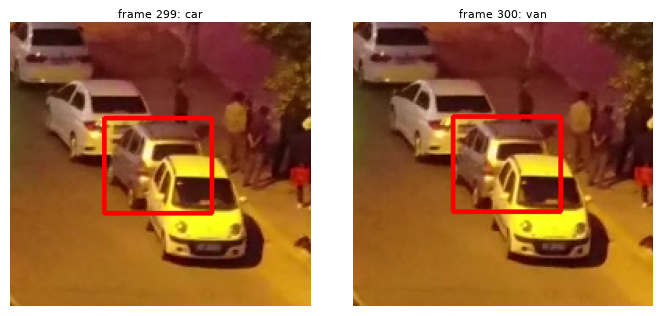

In [14]:
units = metadata.rows_at("unit").group_by("item_index").agg(pl.col("unit_index").min().alias("first_unit"))
detections = (
    metadata
    .rows_at("instance")
    .join(units, on="item_index")
    .with_columns(frame=pl.col("unit_index") - pl.col("first_unit"))
)


def track_path(item: int, track: int) -> pl.DataFrame:
    """Every detection of one track, in frame order."""
    return detections.filter((pl.col("item_index") == item) & (pl.col("track_id") == track)).sort("frame")


def window(item: int, around: list[list[float]], pad: int) -> tuple[int, int, int, int]:
    """The rectangle around some boxes, grown by `pad` pixels and kept inside the frame."""
    size = videos.filter(pl.col("item_index") == item).row(0, named=True)
    x0 = max(int(min(b[0] for b in around)) - pad, 0)
    y0 = max(int(min(b[1] for b in around)) - pad, 0)
    x1 = min(int(max(b[2] for b in around)) + pad, size["width"])
    y1 = min(int(max(b[3] for b in around)) + pad, size["height"])
    return x0, y0, x1, y1


night_item = item_of["uav0000117_02622_v"]
path = track_path(night_item, 87)
after = path.filter(pl.col("class_label") != pl.col("class_label").shift(1)).row(0, named=True)
before = path.filter(pl.col("frame") < after["frame"]).row(-1, named=True)
area = window(night_item, [before["box"], after["box"]], pad=60)
dep.plot(
    SequenceFrames(View(dataset, Indices([night_item]))),
    figsize=(7, 3.2),
    indices=[before["frame"], after["frame"]],
    images_per_row=2,
    titles=[f"frame {row['frame']}: {dataset.index2label[row['class_label']]}" for row in (before, after)],
    boxes=[[before["box"]], [after["box"]]],
    region=area,
    box_color="red",
)

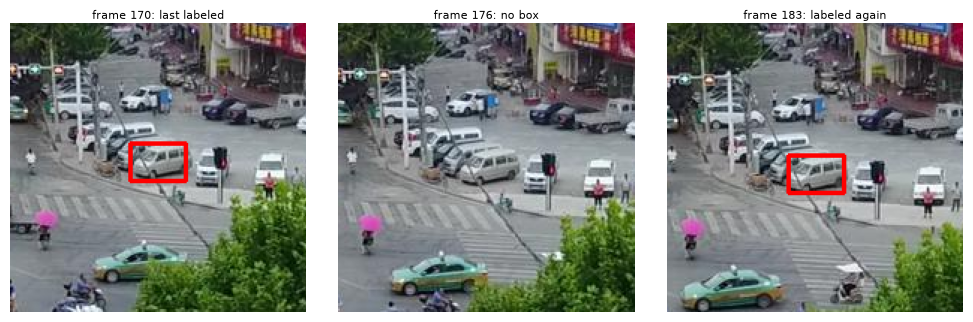

In [15]:
road_path = track_path(road_item, 113)
back = road_path.filter(pl.col("frame") - pl.col("frame").shift(1) > 1).row(0, named=True)
last = road_path.filter(pl.col("frame") < back["frame"]).row(-1, named=True)
middle = (last["frame"] + back["frame"]) // 2
area = window(road_item, [last["box"], back["box"]], pad=80)
shots = (
    (last["frame"], last["box"], "last labeled"),
    (middle, None, "no box"),
    (back["frame"], back["box"], "labeled again"),
)
dep.plot(
    SequenceFrames(View(dataset, Indices([road_item]))),
    figsize=(10, 3.2),
    indices=[frame for frame, _, _ in shots],
    images_per_row=3,
    titles=[f"frame {frame}: {label}" for frame, _, label in shots],
    boxes=[[box] if box is not None else [] for _, box, _ in shots],
    region=area,
    box_color="red",
)

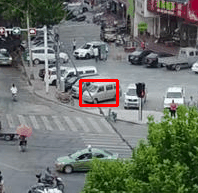

In [16]:
gap = list(range(last["frame"], back["frame"] + 1))
gif = dep.animate(
    SequenceFrames(View(dataset, Indices([road_item]))),
    indices=gap,
    boxes=[[last["box"]]] + [[]] * (len(gap) - 2) + [[back["box"]]],
    region=area,
    box_color="red",
    fps=4,
)
display(gif)

In [17]:
# TEST ASSERTION CELL ###
assert tracks.height == 246
assert flips.height == 6
assert sorted(flips["pair"].to_list()) == ["car/truck"] + ["car/van"] * 5
assert (tracks["n_gaps"] > 0).sum() == 36
assert (tracks["total_gap_length"] > 50).sum() == 10
per_video = tracks.group_by("item_index").agg(pl.len(), (pl.col("n_gaps") > 0).sum().alias("gapped"))
gapped = {r["item_index"]: (r["gapped"], r["len"]) for r in per_video.iter_rows(named=True)}
assert gapped[item_of["uav0000305_00000_v"]] == (17, 48)
assert gapped[item_of["uav0000117_02622_v"]] == (0, 28)
assert after["frame"] - before["frame"] == 1
assert {dataset.index2label[before["class_label"]], dataset.index2label[after["class_label"]]} == {"car", "van"}
assert back["frame"] - last["frame"] - 1 == 12
assert len(gif.data) < 2_000_000

In [18]:
sizes = boxes.group_by("item_index").agg(
    pl.col("box_width").median(),
    pl.col("box_height").median(),
    (pl.col("box_width") / pl.col("width")).median().alias("width_share"),
    ((pl.col("box_width") * pl.col("box_height")) < 32 * 32).mean().alias("under_32"),
)
display(
    videos
    .select("item_index", "video", "width")
    .join(sizes, on="item_index")
    .drop("item_index")
    .rename({"width": "frame_width"})
    .sort("video")
)

video,frame_width,box_width,box_height,width_share,under_32
str,i64,f64,f64,f64,f64
"""uav0000117_02622_v""",2720,79.0,74.0,0.029044,0.021253
"""uav0000137_00458_v""",2688,108.0,75.0,0.040179,0.0
"""uav0000182_00000_v""",1344,44.0,31.0,0.032738,0.346949
"""uav0000268_05773_v""",3840,71.0,38.0,0.01849,0.008932
"""uav0000305_00000_v""",1904,93.0,98.0,0.048845,0.000222
"""uav0000339_00001_v""",1904,88.0,48.0,0.046218,0.092172


In [19]:
frame_view = SequenceFrames(dataset)
covered = image_stats(frame_view, stats=ImageStats.SPATIAL_COVERED_FRACTION, per_image=False)
metadata.add_factors(covered, source_index=frame_view.to_source(covered["source_index"]))
crowding = (
    metadata
    .rows_at("instance")
    .filter(pl.col("class_label").is_in(vehicle_ids))
    .group_by("item_index")
    .agg((pl.col("covered_fraction").fill_nan(None) > 0.5).mean().alias("over_half"))
)
display(videos.select("item_index", "video").join(crowding, on="item_index").drop("item_index").sort("video"))

video,over_half
str,f64
"""uav0000117_02622_v""",0.048501
"""uav0000137_00458_v""",0.236402
"""uav0000182_00000_v""",0.153846
"""uav0000268_05773_v""",0.129376
"""uav0000305_00000_v""",0.007778
"""uav0000339_00001_v""",0.069697


In [20]:
# TEST ASSERTION CELL ###
s = {r["item_index"]: r for r in sizes.iter_rows(named=True)}
small, big = item_of["uav0000182_00000_v"], item_of["uav0000268_05773_v"]
assert (round(s[small]["box_width"]), round(s[small]["box_height"])) == (44, 31)
assert 0.34 <= s[small]["under_32"] <= 0.36
assert (round(s[big]["box_width"]), round(s[big]["box_height"])) == (71, 38)
assert s[big]["width_share"] < 0.02
assert all(71 <= round(r["box_width"]) <= 108 for k, r in s.items() if k != small)
assert all(0.028 <= r["width_share"] <= 0.05 for k, r in s.items() if k != big)
c = {r["item_index"]: r["over_half"] for r in crowding.iter_rows(named=True)}
busy = item_of["uav0000137_00458_v"]
assert 0.21 <= c[busy] <= 0.27
assert all(v <= 0.16 for k, v in c.items() if k != busy)